# Partículas en un chancador de mandíbulas de laboratorio: qué agrega seguir cada partícula a un balance poblacional, y qué midieron los ensayos de laboratorio

**Pregunta:** ¿Qué agrega seguir cada partícula a un balance poblacional de un chancador, y qué midieron los ensayos de Barrios et al. (2020) con el chancador de mandíbulas de laboratorio, que una simulación de partículas debe enfrentar?

- **Nivel:** 1, fundamentos
- **Requisitos previos:** ninguno dentro de este tema; los temas 03 y 04 dan el balance poblacional y el modelo de capacidad que este tema pone junto a la simulación de partículas
- **Tiempo de lectura:** unos 50 minutos (el lote en vivo toma cerca de un minuto)

## Objetivos

Al terminar este notebook puedes:

- decir qué supone un balance poblacional de un chancador sobre la cámara y qué agrega una simulación por elementos discretos al seguir cada partícula;
- enunciar la máquina, las tres alimentaciones estrechas y los tres tipos de medición de los ensayos del chancador de laboratorio, con la página del artículo de donde se leyó cada número;
- escribir las dos leyes que forman el método, la segunda ley de Newton con el contacto de Hertz para cada esfera y la condición de fractura de una esfera frente a su energía de fractura, con cada símbolo definido;
- correr el caso del chancador de laboratorio del paquete con un lote de 0,5 kg, leer qué hizo cada golpe con la masa, la potencia de la placa y el traslape, y decir por qué un lote tan pequeño no se puede enfrentar a la medición.

## Preparación

El motor de partículas es el paquete publicado `crushdem` (versión 0.6.0), instalado con sus núcleos compilados para CPU; numba y llvmlite están fijados en las versiones que usa el cálculo fuera de línea del producto.

```bash
pip install "crushdem[jit]==0.6.0" numba==0.68.1 llvmlite==0.50.0 numpy==2.4.6 matplotlib==3.11.2
```

La celda imprime las versiones, encuentra la raíz del repositorio e importa el caso del chancador de laboratorio del paquete (`crushdem.cases.barrios2020`), su protocolo de comparación, sus funciones de contacto y de fractura, y los tres puntos de operación del cálculo del producto (`pipeline.dem.points`).

In [1]:
# Imprime las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import contextlib
import importlib.metadata as md
import io
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('crushdem', 'numba', 'llvmlite', 'numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas: el notebook no define ningún método propio
from crushdem import comparison
from crushdem.breakage import breakage_probability, fracture_energy_from_probability, median_fracture_energy
from crushdem.cases import barrios2020 as case
from crushdem.core.materials import effective_modulus, energy_share, tsuji_alpha
from crushdem.core.state import rayleigh_time_step
from pipeline.dem import points as P
plt.rcParams.update({"figure.figsize": (8.6, 3.8), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

crushdem 0.6.0
numba 0.68.1
llvmlite 0.50.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Las mediciones del chancador de mandíbulas de laboratorio de Barrios, Jimenez-Herrera, Fuentes-Torres y Tavares (2020), Minerals 10(8), 717, https://doi.org/10.3390/min10080717, de acceso abierto con licencia CC BY 4,0 (`conventions/third-party-datasets.md`). El artículo imprime la máquina en su Tabla 2 (página 3) y entrega los resultados como figuras; el paquete guarda las figuras digitalizadas dos veces, con su diferencia como ruido de digitalización, como datos del paquete (`crushdem/cases/data/barrios2020_digitised.json`), y `crushdem.cases.barrios2020.measured` las devuelve por clase de alimentación. Solo la celda de costo del método lee un archivo de este repositorio, el documento versionado del cálculo.

Los ensayos chancaron lotes de cerca de 6 kg con un solo ajuste: una frecuencia de golpe de 6,0 Hz y un lado cerrado de 7,5 mm. Se usaron tres alimentaciones estrechas, 63/52, 31,5/26,5 y 16/13,2 mm, nombradas por el tamiz superior e inferior. El caudal se midió con una celda de carga integradora, la potencia neta con un multímetro de amperaje y el producto con una pila de tamices de laboratorio (página 3). La primera celda imprime la máquina de la Tabla 2.

In [2]:
# La máquina de la Tabla 2 del artículo, tal como la guarda el paquete
table_2 = case.PAPER["machine_table_2_p3"]
opening = table_2["feed_opening_mm"]
print(f"abertura de alimentación {opening[0]:g} x {opening[1]:g} mm,",
      f"lado cerrado {table_2['discharge_opening_closed_mm'][1]:g} mm,",
      f"carrera {table_2['swing_jaw_throw_mm']:g} mm,",
      f"frecuencia de golpe {table_2['swing_jaw_stroke_frequency_hz']:g} Hz")
print(f"caudal nominal {table_2['nominal_throughput_kg_h']:g} kg/h,",
      f"motor {table_2['motor_power_kw']:g} kW,",
      f"eje principal {table_2['main_shaft_rpm']:g} rpm,",
      f"lado abierto (lado cerrado más carrera) {case.OPEN_SIDE_MM:g} mm")

abertura de alimentación 140 x 90 mm, lado cerrado 7.5 mm, carrera 10 mm, frecuencia de golpe 6 Hz
caudal nominal 300 kg/h, motor 2.2 kW, eje principal 400 rpm, lado abierto (lado cerrado más carrera) 17.5 mm


La segunda celda de lectura toma las tres clases de alimentación de los puntos de operación del producto y, para cada una, el caudal, la potencia neta y la curva de producto medidos que devuelve `measured`, con la página del artículo que contiene la potencia.

In [3]:
# Una fila por alimentación: el caudal, la potencia neta y la curva de producto medidos que guarda el paquete
feeds = [p.feed_class for p in P.POINTS]
measured = {fc: case.measured(fc) for fc in feeds}
mean_size_mm = {fc: 0.5 * (p.lower_mm + p.upper_mm) for fc, p in zip(feeds, P.POINTS)}
print("alim. [mm]  tamaño medio [mm]  caudal [kg/h]  potencia neta [kW]  página")
for fc in feeds:
    m = measured[fc]
    print(f"{fc:>10s} {mean_size_mm[fc]:14.1f} {m.throughput_kg_h:18.1f} {m.net_power_kw:14.4f} {m.net_power_page:10d}")

alim. [mm]  tamaño medio [mm]  caudal [kg/h]  potencia neta [kW]  página
     63/52           57.5              798.7         0.3400         10
 31.5/26.5           29.0              937.2         0.1656         12
   16/13.2           14.6             1220.4         0.1346         12


Lo medido es un número de caudal y uno de potencia neta por alimentación (las barras son la diferencia entre las dos pasadas de digitalización, menor que el ancho de un marcador), y una curva de producto por alimentación. La potencia neta de la alimentación más gruesa son los 0,34 kW que el artículo declara en su texto; las otras dos potencias se leen de la Fig. 14b. La celda siguiente convierte los dos números de cada alimentación en una energía específica, la energía que la máquina toma por kilogramo que pasa, y pone el caudal frente al nominal de 300 kg/h de la Tabla 2.

In [4]:
# La energía específica que implican las mediciones: potencia neta sobre caudal, en J/kg y kWh/t
nominal = case.PAPER["machine_table_2_p3"]["nominal_throughput_kg_h"]
for fc in feeds:
    m = measured[fc]
    j_per_kg = m.net_power_kw * 1000.0 * 3600.0 / m.throughput_kg_h
    ratio = m.throughput_kg_h / nominal
    print(f"{fc:>10s}: {j_per_kg:7.0f} J/kg = {j_per_kg / 3600.0:6.3f} kWh/t;",
          f"caudal sobre el nominal {ratio:4.2f}")

     63/52:    1533 J/kg =  0.426 kWh/t; caudal sobre el nominal 2.66
 31.5/26.5:     636 J/kg =  0.177 kWh/t; caudal sobre el nominal 3.12
   16/13.2:     397 J/kg =  0.110 kWh/t; caudal sobre el nominal 4.07


La figura 1 grafica las dos series frente al tamaño medio de cada alimentación (57,5, 29,0 y 14,6 mm), con el caudal nominal de la máquina como línea segmentada.

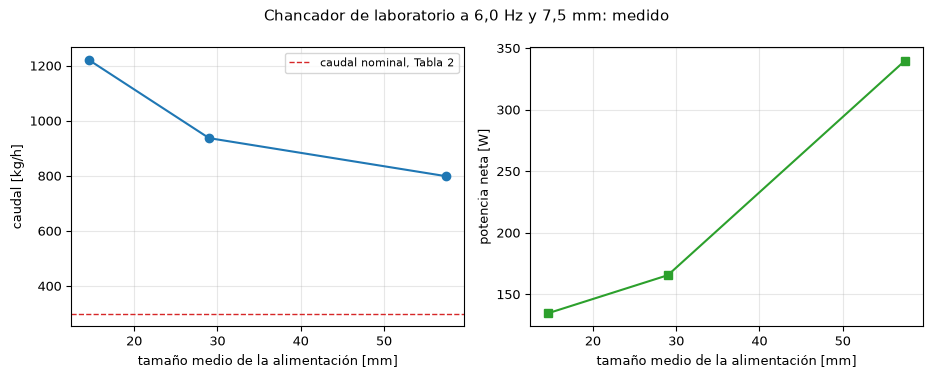

In [5]:
# Figura 1: el caudal y la potencia neta medidos de las tres alimentaciones frente a su tamaño medio
sizes = [mean_size_mm[fc] for fc in feeds]
q = [measured[fc].throughput_kg_h for fc in feeds]
q_noise = [measured[fc].throughput_noise_kg_h for fc in feeds]
power_w = [measured[fc].net_power_kw * 1000 for fc in feeds]
power_noise = [measured[fc].net_power_noise_kw * 1000 for fc in feeds]
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8))
axes[0].errorbar(sizes, q, yerr=q_noise, fmt="o-", capsize=3)
axes[0].axhline(nominal, color="tab:red", ls="--", lw=1, label="caudal nominal, Tabla 2")
axes[0].set_xlabel("tamaño medio de la alimentación [mm]")
axes[0].set_ylabel("caudal [kg/h]")
axes[0].legend(fontsize=8)
axes[1].errorbar(sizes, power_w, yerr=power_noise, fmt="s-", color="tab:green", capsize=3)
axes[1].set_xlabel("tamaño medio de la alimentación [mm]")
axes[1].set_ylabel("potencia neta [W]")
fig.suptitle("Chancador de laboratorio a 6,0 Hz y 7,5 mm: medido")
fig.tight_layout()
plt.show()

Lectura de la figura 1: cuanto más fina la alimentación, más pasa la máquina, 798,7 kg/h para la alimentación 63/52 mm frente a 1220,4 kg/h para la de 16/13,2 mm, y menos potencia toma, 0,34 kW frente a 0,1346 kW. Los tres caudales quedan entre 2,66 y 4,07 veces sobre los 300 kg/h nominales de la tabla de la máquina. La energía específica impresa arriba cae entonces en un factor cercano a cuatro desde la alimentación más gruesa a la más fina, de 1533 a 397 J/kg: una partícula gruesa necesita más golpes de chancado, y la energía lo sigue. La figura no muestra cómo varía la potencia dentro de un ensayo (el artículo la grafica durante 25 s, Fig. 12a), ni ninguna medición con otra frecuencia o ajuste, porque el artículo no hizo ninguna; los barridos de sus Figs. 15 a 17 son simulaciones.

La figura 2 dibuja las tres curvas de producto de la Fig. 7a, y la celda lee de cada una los tamaños al 50 y al 80 por ciento pasante por interpolación lineal entre tamices; P80 es el tamaño que informa un balance poblacional y sobre el que se construye una razón de reducción, el F80 de la alimentación sobre el P80 del producto.

     63/52: P50  4.46 mm, P80  7.12 mm, ruido de digitalización, a lo más 0.42 puntos
 31.5/26.5: P50  4.83 mm, P80  7.62 mm, ruido de digitalización, a lo más 0.16 puntos
   16/13.2: P50  5.15 mm, P80  7.83 mm, ruido de digitalización, a lo más 0.30 puntos


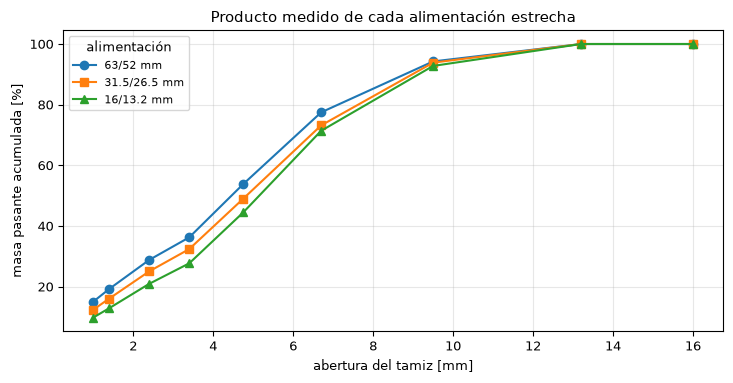

In [6]:
# Figura 2: las tres curvas de producto medidas; P50 y P80 se leen de cada una por interpolación lineal
fig, ax = plt.subplots(figsize=(7.4, 3.9))
marks = {"63/52": "o", "31.5/26.5": "s", "16/13.2": "^"}
for fc in feeds:
    prod = measured[fc].product
    ax.plot(prod["sizes_mm"], prod["passing_pct"], marks[fc] + "-", label=fc + " mm")
    p50 = float(np.interp(50.0, prod["passing_pct"], prod["sizes_mm"]))
    p80 = float(np.interp(80.0, prod["passing_pct"], prod["sizes_mm"]))
    print(f"{fc:>10s}: P50 {p50:5.2f} mm, P80 {p80:5.2f} mm,",
          f"ruido de digitalización, a lo más {prod['noise_pct_max']:.2f} puntos")
ax.set_xlabel("abertura del tamiz [mm]")
ax.set_ylabel("masa pasante acumulada [%]")
ax.set_title("Producto medido de cada alimentación estrecha")
ax.legend(title="alimentación", fontsize=8)
fig.tight_layout()
plt.show()

Lectura de la figura 2: cada producto está enteramente bajo 16 mm, y las tres curvas son cercanas, con P80 entre 7,1 y 7,8 mm para alimentaciones cuyos tamaños superiores son 63, 31,5 y 16 mm; una alimentación cuatro veces más gruesa da un producto solo cerca de un 10 por ciento más grueso. El producto guarda entonces poca memoria de la alimentación y mucha del ajuste, que es lo que codifican los dos parámetros de clasificación de un balance poblacional. La figura no muestra exactamente el punto del 100 por ciento de los tamices más finos: los marcadores de 13,2 y 16 mm del artículo quedan sobre la línea del 100 por ciento bajo otros marcadores, y el paquete los toma como 100.

## Método

### Por qué seguir cada partícula

Un balance poblacional de un chancador, como el modelo de Whiten del tema 03, trata la cámara como un solo lugar con dos funciones: una curva de clasificación que dice qué tamaños se capturan y una función de fractura que dice en qué se convierte una partícula capturada (Whiten, 1972). Sus constantes se ajustan por máquina y roca, y la geometría, el golpe y los contactos entran solo a través de ellas. Eso lo hace barato, una solución lineal, y ciego a lo que ocurre entre las placas. Una simulación por elementos discretos devuelve a la cámara su mecánica: cada partícula es una esfera con posición, velocidad y giro, las placas se mueven con la ley propia de la máquina, el caudal es la masa que cae por la abertura, la potencia es la fuerza de la placa móvil sobre el lecho por su velocidad, y el producto es lo que producen los eventos de fractura. Cleary y Sinnott (2015) construyeron chancadores de compresión así, reemplazando una esfera por sus fragmentos cuando sus contactos reciben energía suficiente, y Barrios et al. (2020) lo hicieron para el chancador de mandíbulas de este notebook.

El precio es la cantidad de cosas que se siguen. Una esfera de la alimentación más fina tiene un paso de tiempo de 3,559 microsegundos, fijado por la velocidad con que una onda de tensión cruza la esfera más pequeña, de modo que un golpe del chancador a 6,0 Hz necesita decenas de miles de pasos, y cada uno visita todos los contactos. Quist (2012) informa 172 y 404 horas de CPU en 8 núcleos para un cuarto de un chancador de cono industrial con 50 364 y 92 508 partículas ligadas, y el lote completo de 6 kg de la alimentación más gruesa del propio paquete toma unos 80 golpes de 10 a 40 s de reloj cada uno en la ruta de CPU (el README del paquete, https://pypi.org/project/crushdem/). Un balance poblacional responde en milisegundos; este notebook debe decir qué compra el costo adicional.

### Las dos leyes del método

Cada esfera $i$ obedece la segunda ley de Newton para su traslación y su giro, con las fuerzas de sus contactos, de la gravedad y de las paredes:

$$m_i \frac{d\mathbf v_i}{dt} = m_i \mathbf g + \sum_{j} \left(F_{n,ij}\,\mathbf n_{ij} + \mathbf F_{t,ij}\right) + \sum_{w} \mathbf F_{iw}, \qquad I_i \frac{d\boldsymbol\omega_i}{dt} = \sum_j R_i\, \mathbf n_{ij} \times \mathbf F_{t,ij},$$

donde $m_i$, $I_i$ y $R_i$ son la masa, el momento de inercia y el radio de la esfera, $\mathbf v_i$ y $\boldsymbol\omega_i$ su velocidad y su giro, $\mathbf g$ la gravedad, $\mathbf n_{ij}$ la normal unitaria de $i$ a $j$, $F_{n,ij}$ y $\mathbf F_{t,ij}$ las fuerzas de contacto normal y tangencial y $\mathbf F_{iw}$ la fuerza de una pared. La fuerza normal es la ley de Hertz con el amortiguamiento de Tsuji, Tanaka e Ishida (1992), según el modelo de contacto de Cundall y Strack (1979):

$$F_n = \tfrac{4}{3} E^{*} \sqrt{R^{*}}\,\delta^{3/2} + \eta_n v_n, \qquad \eta_n = \alpha(e)\sqrt{m^{*} k_{nd}}, \quad k_{nd} = \tfrac{4}{3} E^{*} \sqrt{R^{*}\delta},$$

con $\delta$ el traslape de las dos esferas, $E^{*}$ y $R^{*}$ su módulo y radio efectivos, $v_n$ la velocidad de aproximación de los contactos, $m^{*}$ la masa reducida, $e$ el coeficiente de restitución y $\alpha(e)$ la constante de amortiguamiento ajustada por Tsuji et al. El traslape es un artificio del método, porque la roca real no se interpenetra; representa la deformación elástica, y el método sigue siendo válido solo mientras sea una fracción pequeña del radio. El paquete rechaza una corrida cuyo mayor traslape pasa una fracción dada del radio menor (0,3 salvo que se indique otra), y los notebooks siguientes del tema 09 muestran que ese es el límite que alcanza el chancador.

La segunda ley es la condición de fractura. Una esfera recibe la energía con que sus contactos hacen trabajo mientras la cargan. Tavares (2022) modela la energía de fractura específica $E$ de una partícula de tamaño $d$ como una distribución lognormal:

$$P(E) = \tfrac{1}{2}\left[1 + \operatorname{erf}\!\left(\frac{\ln E - \ln E_{50}(d)}{\sqrt{2\sigma^{2}}}\right)\right], \qquad E_{50}(d) = E_\infty\left[1 + \left(\frac{d_0}{d}\right)^{\phi}\right],$$

donde $E_{50}$ es la energía de fractura mediana [J/kg], $\sigma^{2}$ la varianza de su logaritmo y $E_\infty$, $d_0$ y $\phi$ los parámetros del efecto de tamaño, siendo las partículas pequeñas más resistentes por unidad de masa. Cada esfera sortea un número uniforme $u$ al aparecer; su energía de fractura es la energía donde $P(E) = u$, y se rompe en un evento de energía específica $E_k$ exactamente cuando $e\,E_k \ge E_{\text{frac}}\,(1 - D)$, con $e$ la fracción del trabajo de contacto que entra a la esfera y $D$ el daño que dejaron en ella eventos anteriores más débiles. La esfera se reemplaza entonces por esferas menores que llevan la misma masa, cuyos tamaños salen de la energía del evento (el tema del notebook 02).

La celda evalúa el contacto del chancador con las funciones del paquete. La roca y el acero son los dos materiales de las Tablas 3 y 4 del artículo tal como los guarda `crushdem.cases.barrios2020`; la celda imprime el módulo efectivo de la roca contra el acero, la fracción del trabajo de contacto que entra a la roca (la ecuación 9 de Tavares), la constante de amortiguamiento con la restitución roca-acero de 0,37, el paso de tiempo estable con un décimo del tiempo de Rayleigh de una esfera de 16 mm y una de 4 mm, y la fuerza de Hertz de una esfera de 14,6 mm apretada 0,05 mm contra una placa de acero.

In [7]:
# El contacto del chancador con el paquete: módulo efectivo, fracción de energía, amortiguamiento, paso de tiempo
ore_mat, steel_mat = case.ORE_MATERIAL, case.STEEL_MATERIAL
e_star = effective_modulus(ore_mat, steel_mat)
share = energy_share(ore_mat, steel_mat)
print(f"E* roca contra acero {e_star:.4g} Pa,",
      f"fracción de energía de la roca e = {share:.4f}")
print(f"constante de Tsuji con restitución 0,37: alpha = {tsuji_alpha(0.37):.4f}")
for d_mm in (16.0, 4.0):
    dt_r = rayleigh_time_step(0.5 * d_mm * 1e-3, ore_mat)
    print(f"tiempo de Rayleigh de una esfera de {d_mm:g} mm: {dt_r:.3e} s ({dt_r * 1e6:.2f} us),",
          f"un décimo {0.1 * dt_r:.3e} s = {0.1 * dt_r * 1e6:.3f} microsegundos")
# Fuerza de Hertz de una esfera de roca de 14,6 mm apretada 0,05 mm contra acero (R* es el radio de la esfera)
radius, overlap = 0.5 * mean_size_mm["16/13.2"] * 1e-3, 5.0e-5
force = 4.0 / 3.0 * e_star * np.sqrt(radius) * overlap ** 1.5
print(f"Fuerza de Hertz con un traslape de {overlap * 1e3:.2f} mm",
      f"({overlap / radius * 100:.2f} por ciento del radio): {force:.1f} N")

E* roca contra acero 2.632e+08 Pa, fracción de energía de la roca e = 0.9868
constante de Tsuji con restitución 0,37: alpha = 0.6757
tiempo de Rayleigh de una esfera de 16 mm: 1.424e-04 s (142.36 us), un décimo 1.424e-05 s = 14.236 microsegundos
tiempo de Rayleigh de una esfera de 4 mm: 3.559e-05 s (35.59 us), un décimo 3.559e-06 s = 3.559 microsegundos
Fuerza de Hertz con un traslape de 0.05 mm (0.68 por ciento del radio): 10.6 N


El módulo efectivo es 2,632e+08 Pa y la roca recibe 0,9868 del trabajo de contacto, porque el acero es tanto más rígido que casi todo deforma la roca. Una esfera de 14,6 mm apretada 0,05 mm, el 0,68 por ciento de su radio, soporta una fuerza de 10,6 N; la fuerza crece con el traslape elevado a 3/2, así que un traslape diez veces mayor soporta unas 32 veces más. El tiempo de Rayleigh de la esfera de 4 mm que el producto conserva como la menor, 35,59 microsegundos, es lo que fija el paso de 3,559 microsegundos usado en todo el notebook, un décimo de él.

La celda siguiente toma la roca del artículo tal como la deriva el paquete de los 30 ensayos de una partícula por clase de tamaño de la Fig. 6b del artículo (el notebook 02 sigue la derivación) y evalúa la condición de fractura en una esfera de la alimentación 16/13,2 mm: su energía de fractura mediana, la probabilidad de romperse con eventos de un cuarto a cuatro veces esa energía, y la energía de fractura de esferas cuyo sorteo es 0,1, 0,5 y 0,9.

In [8]:
# La roca del artículo tal como la deriva el paquete de los ensayos de una partícula, y la ley de fractura en una
# esfera
ore, derivation = case.paper_ore("A", seed=1)
d_sphere = mean_size_mm["16/13.2"] * 1e-3
e50 = median_fracture_energy(d_sphere, ore)
print(f"energía de fractura mediana a {d_sphere * 1e3:.1f} mm: E50 = {e50:.1f} J/kg,",
      f"varianza del logaritmo {ore.variance:.2f}")
print("E50 de las tres clases de ensayo de una partícula [J/kg]:",
      {k: round(v, 1) for k, v in derivation["e50_j_kg"].items()})
print("energía del evento [J/kg]   probabilidad de fractura")
for factor in (0.25, 0.5, 1.0, 2.0, 4.0):
    print(f"{factor * e50:14.1f} {breakage_probability(factor * e50, d_sphere, ore):20.3f}")
# Un sorteo uniforme por esfera fija su energía de fractura, la inversa de esa probabilidad
for u in (0.1, 0.5, 0.9):
    energy_u = fracture_energy_from_probability(u, d_sphere, ore)
    print(f"u = {u}: energía de fractura {energy_u:.1f} J/kg")
spread = fracture_energy_from_probability(0.9, d_sphere, ore) / fracture_energy_from_probability(0.1, d_sphere, ore)
print(f"razón de energías de fractura con u = 0,9 y u = 0,1: {spread:.2f}")

energía de fractura mediana a 14.6 mm: E50 = 168.6 J/kg, varianza del logaritmo 1.20
E50 de las tres clases de ensayo de una partícula [J/kg]: {'63/53': 26.6, '31.5/26.5': 58.2, '16.0/13.2': 451.1}
energía del evento [J/kg]   probabilidad de fractura
          42.2                0.103
          84.3                0.263
         168.6                0.500
         337.2                0.737
         674.4                0.897
u = 0.1: energía de fractura 41.4 J/kg
u = 0.5: energía de fractura 168.6 J/kg
u = 0.9: energía de fractura 686.4 J/kg
razón de energías de fractura con u = 0,9 y u = 0,1: 16.57


La energía de fractura mediana de una esfera de 14,6 mm es 168,6 J/kg, y la varianza del logaritmo de 1,20 es amplia: un evento a un cuarto de la mediana rompe una esfera de cada diez, uno a cuatro veces la mediana deja una de cada diez sin romper, y las esferas en los extremos del sorteo difieren en un factor de 16,57 en energía de fractura (41,4 frente a 686,4 J/kg). Dos esferas de un mismo tamaño, en el mismo contacto, se rompen entonces en momentos distintos, que es como una ley de contacto determinista y una resistencia aleatoria dan la dispersión que muestra un lote real. La mediana es grande junto a los 26,6 y 58,2 J/kg de las clases 63/53 y 31,5/26,5 mm, porque el efecto de tamaño hace fuertes a las partículas pequeñas por unidad de masa; esa es la extrapolación en que descansa la alimentación más fina y el notebook 02 vuelve sobre ella.

### Un primer lote en vivo

La celda corre el ciclo de golpes propio del paquete en el chancador de laboratorio: `run_attempt` construye el chancador y su tabla de contactos, alimenta 0,5 kg de la alimentación 16/13,2 mm, corre un golpe a la vez y registra después de cada uno la masa retenida en la cámara, la masa pasada, la potencia media de la placa oscilante y el mayor traslape visto. Se detiene cuando el lote salió, cuando nada pasa durante 40 golpes, o en el límite de golpes, seis aquí. Los argumentos son la roca, la masa del lote, la frecuencia de golpe, la semilla, el número de casillas para partículas, el límite de traslape (0,5 aquí, el tope de la escalera que usa el cálculo del producto), el backend y los límites de la corrida. El paquete imprime su propia línea de avance con un reloj de pared, y la celda la silencia para que la salida sea la misma en cada corrida.

In [9]:
# Un lote en vivo: 0,5 kg de la alimentación 16/13,2 mm, seis golpes como máximo, con el control del paquete; se
# silencia su línea de avance
with contextlib.redirect_stdout(io.StringIO()):
    attempt = case.run_attempt(ore, 0.5, 6.0, 1, 800, 0.5, "numba", 6, 600.0, 40, feed_class="16/13.2")
steps_per_stroke = attempt["steps"] // attempt["strokes"]
print("estado:", attempt["status"], "|", attempt["strokes"], "golpes,", attempt["steps"],
      "pasos de", f"{attempt['dt_s']:.3e}", "s,", steps_per_stroke, "pasos por golpe")
print("golpe  esferas ret.  ret. [kg]  pasada [kg]  placa [W]  mayor traslape")
for row in attempt["series"]:
    print(f"{row['stroke']:6d} {row['n_hold']:13d} {row['hold_up_kg']:11.3f} {row['passed_kg']:11.3f}",
          f"{row['swing_plate_w']:15.1f} {row['max_overlap']:16.3f}")

estado: complete | 6 golpes, 280986 pasos de 3.559e-06 s, 46831 pasos por golpe
golpe  esferas ret.  ret. [kg]  pasada [kg]  placa [W]  mayor traslape
     1           113       0.499       0.000             0.0            0.009
     2           115       0.350       0.149           102.2            0.267
     3            82       0.222       0.277            62.2            0.221
     4            62       0.100       0.400           124.3            0.313
     5             6       0.010       0.490            -9.7            0.199
     6             0       0.000       0.499            -0.0            0.022


La figura 3 dibuja la misma serie: la masa retenida y pasada, la potencia media de la placa en cada golpe y el mayor traslape, con el límite de 0,3 del modelo de contacto como línea segmentada.

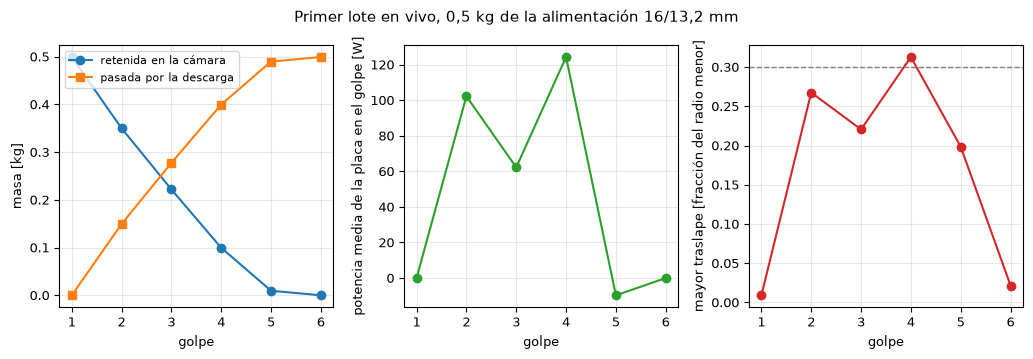

In [10]:
# Figura 3: lo que hicieron los golpes, de la serie por golpe de la corrida
rows = attempt["series"]
stroke = [r["stroke"] for r in rows]
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.6))
axes[0].plot(stroke, [r["hold_up_kg"] for r in rows], "o-", label="retenida en la cámara")
axes[0].plot(stroke, [r["passed_kg"] for r in rows], "s-", label="pasada por la descarga")
axes[0].set_ylabel("masa [kg]")
axes[0].legend(fontsize=8)
axes[1].plot(stroke, [r["swing_plate_w"] for r in rows], "o-", color="tab:green")
axes[1].set_ylabel("potencia media de la placa en el golpe [W]")
axes[2].plot(stroke, [r["max_overlap"] for r in rows], "o-", color="tab:red")
axes[2].axhline(0.3, color="gray", ls="--", lw=1)
axes[2].set_ylabel("mayor traslape [fracción del radio menor]")
for ax in axes:
    ax.set_xlabel("golpe")
fig.suptitle("Primer lote en vivo, 0,5 kg de la alimentación 16/13,2 mm")
fig.tight_layout()
plt.show()

Lectura de la tabla y de la figura 3. En el golpe 1 las 113 esferas alimentadas (0,499 kg) caen en la cámara y no pasa nada: la placa aún no se ha cerrado sobre ellas y la potencia de la placa es cero. En el golpe 2 la placa trabaja, con 102,2 W en promedio, salen 0,149 kg y el mayor traslape salta de 0,009 a 0,267 del radio menor, que es lo que hace un lecho cargado y no una cámara vacía; los golpes 3 y 4 pasan 0,277 y 0,400 kg en total, con el traslape en 0,221 y luego 0,313, sobre los 0,3 del modelo de contacto. En el golpe 5 solo quedan 6 esferas (0,010 kg) y la potencia de la placa es levemente negativa, -9,7 W, porque la placa ya no empuja un lecho y el promedio del golpe es el movimiento propio de la placa contra los últimos granos; en el golpe 6 no queda nada retenido y el lote está completo. La figura muestra un chancador vacío en los extremos y uno cargado entre ellos; no muestra un estado estable, porque un lote de 0,5 kg desaparece en cuatro golpes, y una potencia media sobre una corrida así no es la media de 25 s de un ensayo de 6 kg.

La última celda del método lee lo que dejó el lote: los conteos de eventos de fractura y de hijas, el balance de masa, y el producto frente a la curva medida de la misma alimentación.

In [11]:
# Lo que dejó el lote: conteos de fractura, balance de masa y producto frente a la curva medida de la misma
# alimentación
brk, prod = attempt["breakage"], attempt["product"]
print(f"eventos {brk['n_events']}, hijas {brk['n_progeny']},",
      f"máximo de esferas {brk['peak_particles']},",
      f"finos bajo 4 mm {brk['fines_kg'] * 1000:.1f} g")
print(f"residuo del balance de masa {attempt['mass_balance_residual_kg']:.1e} kg,",
      f"masa pasada {prod['total_kg']:.3f} kg")
p80_sim = comparison.d_percent(prod, 0.8)
p50_sim = comparison.d_percent(prod, 0.5)
curve = measured["16/13.2"].product
p80_meas = float(np.interp(80.0, curve["passing_pct"], curve["sizes_mm"]))
print(f"simulación de partículas: P50 {p50_sim:.1f} mm, P80 {p80_sim:.1f} mm;",
      f"medición: P80 {p80_meas:.1f} mm")
print(f"esfera mayor que salió {1e3 * max(prod['sizes_m']):.1f} mm",
      f"frente a un lado abierto de {case.OPEN_SIDE_MM:.1f} mm")

eventos 46, hijas 157, máximo de esferas 115, finos bajo 4 mm 8.2 g
residuo del balance de masa 3.0e-16 kg, masa pasada 0.499 kg
simulación de partículas: P50 14.2 mm, P80 15.2 mm; medición: P80 7.8 mm
esfera mayor que salió 15.9 mm frente a un lado abierto de 17.5 mm


El costo del método a tamaño completo está en el documento versionado del cálculo del producto, `data/derived/dem/jaw-lab.json`, que corre estas tres alimentaciones con un lote de 6 kg. La celda imprime, para cada alimentación, cómo terminó la corrida, sus golpes y pasos, el mayor número de esferas vivas y su producto, una cota superior de los pasos de partícula de la corrida.

In [12]:
# Lo que cuestan los mismos lotes a tamaño completo, del documento versionado del cálculo
doc = json.loads((ROOT / "data/derived/dem/jaw-lab.json").read_text(encoding="utf-8"))
print("alim. [mm]  estado  golpes  pasos  máx. esferas  pasos x máx. esferas")
for pt in doc["points"]:
    s = pt["simulation"]
    peak = s["breakage"]["peak_particles"]
    print(f"{pt['feed_class']:>10s} {s['status']:>14s} {s['strokes']:7d} {s['steps']:10d}",
          f"{peak:12d} {s['steps'] * peak:18.3e}")
print("lote alimentado:", [round(pt["simulation"]["mass_fed_kg"], 3) for pt in doc["points"]], "kg")

alim. [mm]  estado  golpes  pasos  máx. esferas  pasos x máx. esferas
     63/52       complete      83    3886973          295          1.147e+09
 31.5/26.5  overlap_error       5     234850          327          7.680e+07
   16/13.2       complete      54    2528874         1341          3.391e+09
lote alimentado: [6.001, 5.992, 5.999] kg


La alimentación gruesa necesita 83 golpes y 3 886 973 pasos, con a lo más 295 esferas vivas, una cota superior de 1,147e+09 pasos de partícula; la fina necesita 54 golpes y 2 528 874 pasos, pero con hasta 1341 esferas, lo que da 3,391e+09. La alimentación intermedia se detuvo tras 5 golpes y 234 850 pasos, con 327 esferas retenidas, y es el primer indicio de que una corrida de tamaño completo puede no terminar; el notebook 02 lee por qué. El costo no sigue entonces el tamaño de la alimentación de forma simple: la gruesa necesita más golpes, la fina muchas más esferas, y el README del paquete pone un golpe de la alimentación gruesa en 10 a 40 s de reloj, de modo que estas corridas quedan muy más allá de lo que un notebook puede esperar. Los 6 kg de cada lote se alimentan con una diferencia de unos pocos gramos: 6,001, 5,992 y 5,999 kg.

## Resultados

**Respuesta:** Seguir cada partícula agrega la mecánica de la cámara que un balance poblacional pliega en dos curvas ajustadas: los 46 eventos de fractura de este lote de 0,5 kg tienen cada uno un lugar, un tiempo y una energía, y la potencia de la placa, 124,3 W en su golpe más alto aquí, sale de la fuerza de la placa sobre el lecho y no de un índice de trabajo. Lo que midieron los ensayos de laboratorio es, para cada una de tres alimentaciones estrechas a 6,0 Hz y 7,5 mm, un caudal de 798,7, 937,2 y 1220,4 kg/h, una potencia neta de 0,34, 0,1656 y 0,1346 kW, y un producto con P80 de 7,12, 7,62 y 7,83 mm.

Dos cosas del lote anterior deben decirse con claridad. Primero, el balance de masa cierra, con un residuo de 3,0e-16 kg, y los 46 eventos y 157 hijas dejan 8,2 g de finos bajo la esfera mínima de 4 mm, así que la regla de reemplazo conserva la masa. Segundo, el producto del lote en vivo es más grueso que el medido: P80 15,2 mm frente a 7,8 mm para la misma alimentación, con esferas de hasta 15,9 mm saliendo por una abertura cuyo lado abierto es 17,5 mm, donde el producto medido no tiene nada sobre 13,2 mm. Un lote de 0,5 kg, unos pocos golpes y ningún estado estable no es un ensayo de la máquina del artículo y esta sola comparación no prueba nada por sí misma; es el primer indicio de una diferencia que los notebooks 02 y 03 siguen con las corridas de tamaño completo y con las otras dos alimentaciones.

Lo que eso cuesta también se lee en la corrida: 280 986 pasos para seis golpes, 46 831 por golpe, sobre a lo más 115 esferas, y 3 886 973 pasos y hasta 1,147e+09 pasos de partícula para el lote completo de 6 kg de la alimentación gruesa, que es por qué el lote completo se lee del documento versionado en lugar de correrse en un notebook.

## Resumen

- Un balance poblacional reemplaza la cámara por dos curvas ajustadas; una simulación por elementos discretos sigue cada esfera con la segunda ley de Newton y el contacto de Hertz y la rompe cuando la energía de su evento pasa su energía de fractura, sorteada de una ley lognormal.
- El chancador de laboratorio de Barrios et al. (2020) se midió con un solo ajuste, 7,5 mm a 6,0 Hz, con tres alimentaciones estrechas: caudal de 2,66 a 4,07 veces el nominal de 300 kg/h, potencia neta que baja de 0,34 a 0,1346 kW al afinarse la alimentación, y todo producto bajo 16 mm con P80 cerca de 7 a 8 mm.
- El paquete corre ese chancador: un lote en vivo de 0,5 kg cerró su balance de masa a 3,0e-16 kg y produjo un producto más grueso que el medido, lo que un lote tan pequeño no puede decidir.
- El costo es el número de pasos, 46 831 pasos por golpe con el paso de 3,559 microsegundos y 3 886 973 pasos para el lote completo de la alimentación gruesa, lo que lo deja fuera del alcance de un notebook.
- El notebook 02 toma la fractura paso a paso y muestra dónde deja de funcionar el método en este chancador; el notebook 03 enfrenta la simulación de partículas a la medición y al balance poblacional con un modelo de capacidad de mandíbulas.

## Referencias

- Barrios, G. K., Jiménez-Herrera, N., Fuentes-Torres, S. N., Tavares, L. M. (2020). DEM simulation of laboratory-scale jaw crushing of a gold-bearing ore using a particle replacement model. Minerals 10(8), 717. https://doi.org/10.3390/min10080717
- Cleary, P. W., Sinnott, M. D. (2015). Simulation of particle flows and breakage in crushers using DEM: Part 1, Compression crushers. Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Cundall, P. A., Strack, O. D. L. (1979). A discrete numerical model for granular assemblies. Geotechnique 29(1), 47-65. https://doi.org/10.1680/geot.1979.29.1.47
- Quist, J. (2012). Cone crusher modelling and simulation. Chalmers University of Technology. http://publications.lib.chalmers.se/records/fulltext/164816/164816.pdf
- Quist, J., Evertsson, C. M. (2016). Cone crusher modelling and simulation using DEM. Minerals Engineering 85, 92-105. https://doi.org/10.1016/j.mineng.2015.11.004
- Santibanez-Leal, F. (2026). crushdem 0.6.0, a soft-sphere discrete element method with particle breakage for crushers, package page and README. https://pypi.org/project/crushdem/
- Tavares, L. M. (2022). Review and further validation of a practical single-particle breakage model. KONA Powder and Particle Journal 39, 62-83. https://doi.org/10.14356/kona.2022012
- Tsuji, Y., Tanaka, T., Ishida, T. (1992). Lagrangian numerical simulation of plug flow of cohesionless particles in a horizontal pipe. Powder Technology 71(3), 239-250. https://doi.org/10.1016/0032-5910(92)88030-L
- Whiten, W. J. (1972). The simulation of crushing plants with models developed using multiple spline regression. Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf